# SEGS: Solar Energy Generating System

The model is implemented as a subclass of
[TESPy](https://github.com/oemof/tespy)'s `ModelTemplate` in
[SEGS.py](./SEGS.py), the exergy analysis is carried out with
[exerpy](https://github.com/oemof/exerpy).

The plant model is validated against an EBSILON model of identical topology,
see the [README](./README.md) for details and references.

In [1]:
from SEGS import SEGSModel

model = SEGSModel()
model.nw.iterinfo = False
model.solve_design()

## Cycle diagrams

The state points and process lines of the water/steam power cycle are shown
in the following two cycle diagrams.

Note, that `SEGSModel` overrides the `create_diagram` method to adjust the
isoline range to the operating envelope of the cycle (5 °C to 550 °C). QT
diagrams of the heat exchangers are available via
`plot_QT_diagram_matplotlib`, but they are not particularly relevant in this
model.

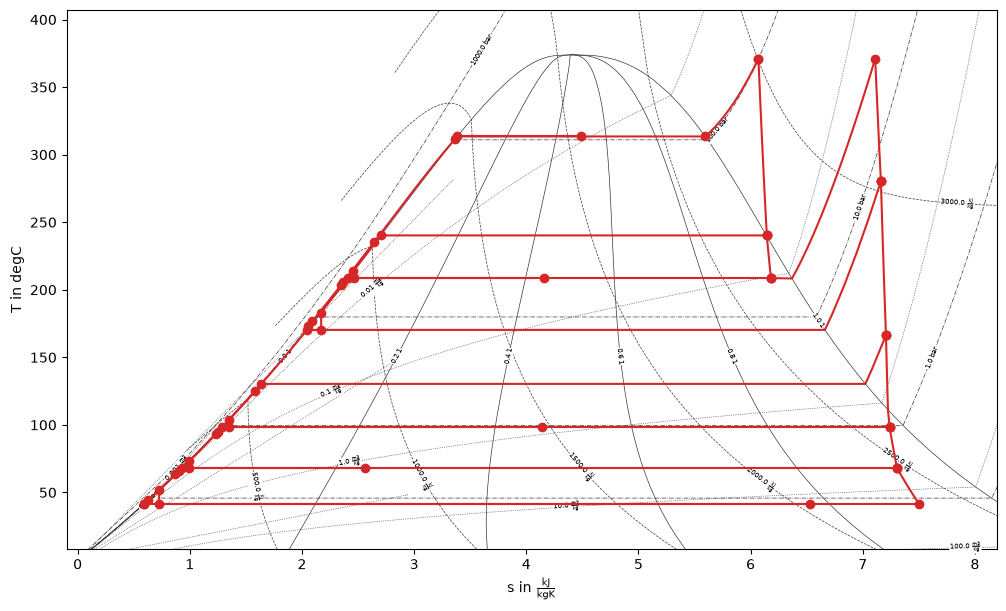

In [2]:
fig, ax = model.plot_Ts_diagram_matplotlib("2", figsize=(12, 7))

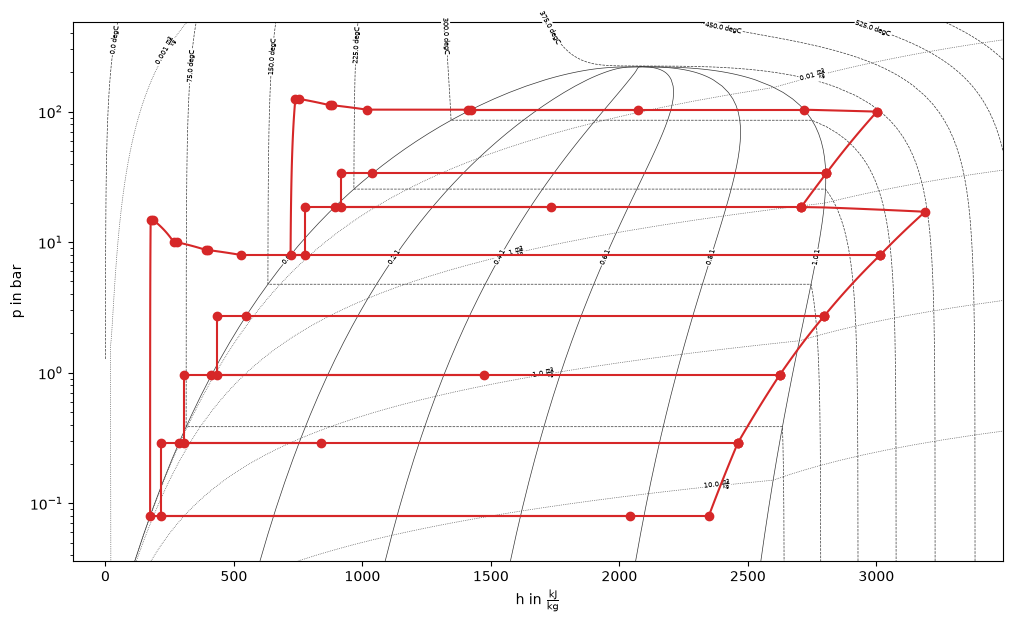

In [3]:
fig, ax = model.plot_logph_diagram_matplotlib("2", figsize=(12, 7))

## Validation

The TESPy results are compared to the results of the EBSILON model:

In [4]:
from SEGS import validate

validate(model)

,TESPy,EBSILON,δ in %
parameter,,,
grid power in MW,31.769,31.769,-0.0
HTF return temperature in °C,296.254,296.254,-0.0


The exergy analysis takes the solar heat input as fuel, the power delivered to
the grid as product and the exergy of the cooling tower air flow as loss:

In [5]:
ean = model.run_exergy_analysis()
df_components, df_connections, df_power = ean.exergy_results(print_results=False)
df_components

,Component,E_F [kW],E_P [kW],E_D [kW],E_L [kW],epsilon [%],y [%],y* [%]
0,Condenser,3066.057056,1559.990252,1506.066804,0.000000,50.879361,3.162212,9.798565
16,Condenser pump,65.605648,46.963681,18.641966,0.000000,71.584815,0.039142,0.121286
6,Cooling tower,1577.526497,NaN,1577.526497,0.000000,NaN,3.312252,10.263486
20,Cooling tower fan,822.720069,493.693903,329.026166,0.000000,60.007519,0.690840,2.140665
17,Cooling water pump,52.567902,37.057704,15.510198,0.000000,70.494927,0.032566,0.100910
...,...,...,...,...,...,...,...,...
56,mot cwp,55.334634,52.567902,2.766732,0.000000,95.000000,0.005809,0.018001
57,mot fan,866.021125,822.720069,43.301056,0.000000,95.000000,0.090917,0.281719
58,mot fwp,761.924147,723.827940,38.096207,0.000000,95.000000,0.079989,0.247856
59,mot ptpump,1789.724800,1700.238560,89.486240,0.000000,95.000000,0.187890,0.582203


## Using the model for your own analyses

You can use this model for own analyses if you are interested. All interaction
happens through named parameters, which are defined in the `_parameter_lookup`
method of the `SEGSModel` class. Find more information on setting these up in
the documentation of tespy.

To adjust the model for your own analysis, extend that dictionary with the
connections or components you are interested in, for example:

```python
"condenser ttd": ["Components", "Condenser", "ttd_u"],
```

These are the parameters currently defined:

In [6]:
list(model.parameter_lookup)

['grid power',
 'solar heat input',
 'live steam pressure',
 'live steam temperature',
 'reheat temperature',
 'condenser pressure',
 'HTF temperature',
 'HTF return temperature',
 'HP turbine 1 mass flow',
 'thermal efficiency']

### Retrieving results

Read a single value with `get_parameter` or several at once with
`get_results`:

In [ ]:
import pandas as pd


pd.Series(model.get_results(list(model.parameter_lookup)))

grid power                3.176885e+07
solar heat input          9.186968e+07
live steam pressure       1.000000e+02
live steam temperature    3.710000e+02
reheat temperature        3.710000e+02
condenser pressure        8.000000e-02
HTF temperature           3.900000e+02
HTF return temperature    2.962539e+02
HP turbine 1 mass flow    3.896900e+01
thermal efficiency        3.458034e-01
dtype: float64

### Solving with an updated input

`solve_model` sets the given parameters and solves the model.

In [8]:
model.solve_model(**{"live steam temperature": 380})
round(model.get_parameter("thermal efficiency"), 4)

0.3472

### Sensitivity analysis

`sensitivity_analysis` solves the model for each value of a parameter sweep and
logs the values of the respective results specified in the result parameter
list.

In [9]:
df = model.sensitivity_analysis(
    param_dict={"live steam pressure": [85.0, 90.0, 95.0, 100.0]},
    result_param_list=["thermal efficiency", "grid power"],
)
df

,live steam pressure,thermal efficiency,grid power
0,85.0,0.342196,3.145241e+07
1,90.0,0.344047,3.167094e+07
2,95.0,0.345713,3.186408e+07
3,100.0,0.347221,3.203521e+07


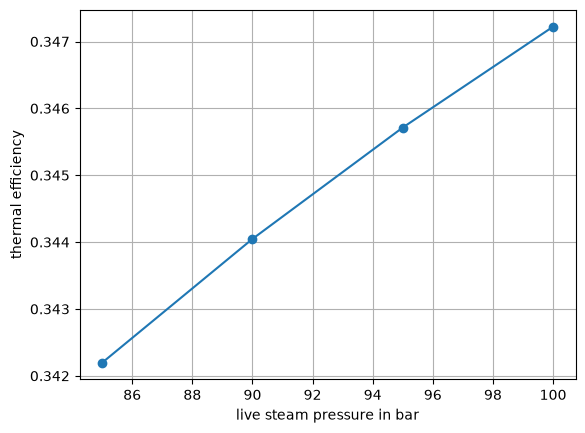

In [10]:
ax = df.set_index("live steam pressure")["thermal efficiency"].plot(
    marker="o", grid=True,
    xlabel="live steam pressure in bar", ylabel="thermal efficiency",
)

# restore the nominal state
model.solve_model(**{"live steam pressure": 100, "live steam temperature": 371})